# Lab 11-01 · Signals: Classification and Operations

Companion to [chapter 11-01](../../chapters/11-01-signals-classification-and-operations.md). Five parts: periods by search, energy and power, time operations, the impulse as a limit, and sampled sinusoids. Run the cells in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

def u(t):
    return np.where(np.asarray(t) > 0, 1.0, 0.0)

def r(t):
    t = np.asarray(t, dtype=float)
    return np.where(t > 0, t, 0.0)

def mismatch(f, T, probe=np.linspace(0, 7.3, 400)):
    """Worst-case difference between f(t + T) and f(t) over a set of probe times."""
    return np.max(np.abs(f(probe + T) - f(probe)))

## Part 1 — Periods by search

A period is a shift that leaves the signal unchanged. Search for the smallest one numerically, then look at a signal that has none.

In [2]:
def ct_period(f, tmax, dt=1e-4):
    left = False
    for T in np.arange(dt, tmax, dt):
        m = mismatch(f, T)
        if not left:
            left = m > 0.1        # leave the trivial neighbourhood of T = 0 first
        elif m < 1e-6:
            return T
    return None

def dt_period(x, nmax=2000):
    n = np.arange(400)
    for N in range(1, nmax):
        if np.max(np.abs(x(n + N) - x(n))) < 1e-9:
            return N
    return None

x1 = lambda t: 3 * np.cos(4 * np.pi * t) + 2 * np.sin(6 * np.pi * t + np.pi / 4)
print("Example 1(a): T0 =", round(ct_period(x1, 3), 4), "s")
print("Example 1(c): N0 =", dt_period(lambda n: np.cos(0.3 * np.pi * n)))
print("Example 1(d): N0 =", dt_period(lambda n: np.cos(0.5 * n)))
print("Example 1(e): N0 =", dt_period(lambda n: np.cos(np.pi * n / 4) + np.sin(np.pi * n / 6)))

Example 1(a): T0 = 1.0 s
Example 1(c): N0 = 20
Example 1(d): N0 = None
Example 1(e): N0 = 24


closest near-period below 30 s: T = 22.000 s, mismatch 0.0177 (never 0)


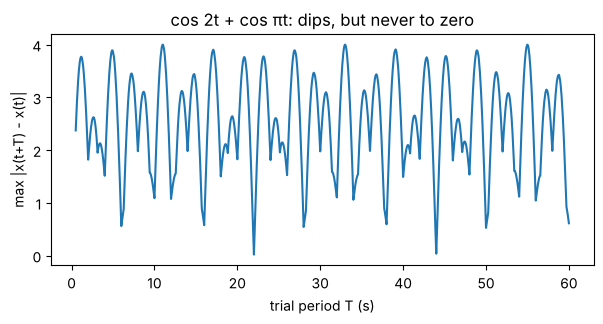

In [3]:
x2 = lambda t: np.cos(2 * t) + np.cos(np.pi * t)
Ts = np.arange(0.5, 60, 2e-3)
mis = np.array([mismatch(x2, T, np.linspace(0, 2 * np.pi * 7, 300)) for T in Ts])
best = Ts[np.argmin(mis[Ts < 30])]
print(f"closest near-period below 30 s: T = {best:.3f} s, mismatch {mis[Ts < 30].min():.4f} (never 0)")
plt.figure(figsize=(7, 3))
plt.plot(Ts, mis)
plt.xlabel("trial period T (s)"); plt.ylabel("max |x(t+T) - x(t)|")
plt.title("cos 2t + cos πt: dips, but never to zero")
plt.show()

## Part 2 — Energy and power

Integrate Example 11-01.2's energy numerically. Then watch the windowed power of a sinusoid converge to 1/2, and compare its error with the bound $1/(8\pi T)$.

In [4]:
E = quad(lambda t: (5 * np.exp(-2 * t)) ** 2, 0, np.inf)[0]
print(f"energy of 5 e^(-2t) u(t): {E:.4f} V^2 s; into 1 kOhm: {E / 1000 * 1e3:.3f} mJ")
print(f"DT energy of 0.8^n u[n]: {sum(0.64 ** n for n in range(500)):.4f}")

def pw(T):
    return 0.5 + np.sin(4 * np.pi * T) / (8 * np.pi * T)   # (1/2T) * integral of cos^2(2 pi t), done by hand

for T in (1.125, 10.125, 100.125):
    num = quad(lambda t: np.cos(2 * np.pi * t) ** 2, -T, T, limit=1000)[0] / (2 * T)
    print(f"T = {T:8.3f} s: numerical {num:.6f}, formula {pw(T):.6f}, bound {1 / (8 * np.pi * T):.6f}")

energy of 5 e^(-2t) u(t): 6.2500 V^2 s; into 1 kOhm: 6.250 mJ
DT energy of 0.8^n u[n]: 2.7778
T =    1.125 s: numerical 0.535368, formula 0.535368, bound 0.035368
T =   10.125 s: numerical 0.503930, formula 0.503930, bound 0.003930
T =  100.125 s: numerical 0.500397, formula 0.500397, bound 0.000397


## Part 3 — Time operations as function composition

$y(t) = x(4 - 2t)$ is a new function that calls $x$. The wrong order, scaling and then shifting by 4, calls $x(8 - 2t)$.

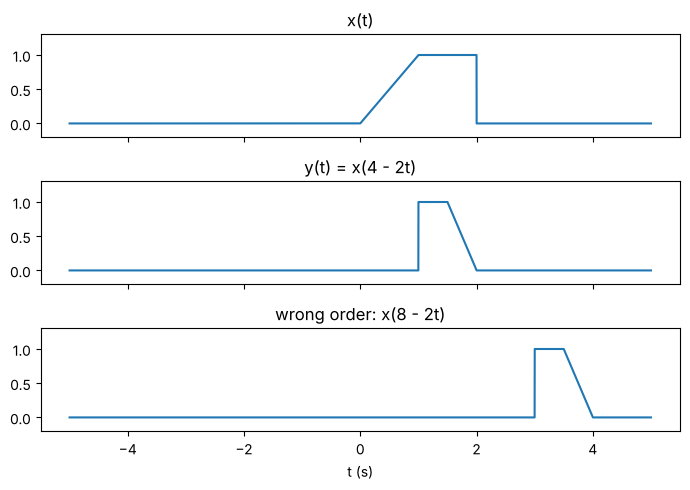

E_x = 1.3333, E_y = 0.6667, ratio 0.5000


In [5]:
x = lambda t: r(t) - r(t - 1) - u(t - 2)
y = lambda t: x(4 - 2 * t)
wrong = lambda t: x(8 - 2 * t)
t = np.linspace(-5, 5, 10001)
fig, axs = plt.subplots(3, 1, figsize=(7, 5), sharex=True)
for ax, f, title in zip(axs, (x, y, wrong), ("x(t)", "y(t) = x(4 - 2t)", "wrong order: x(8 - 2t)")):
    ax.plot(t, f(t)); ax.set_title(title); ax.set_ylim(-0.2, 1.3)
axs[-1].set_xlabel("t (s)")
plt.tight_layout(); plt.show()
Ex = quad(lambda s: float(x(s)) ** 2, -1, 3, points=[0, 1, 2])[0]
Ey = quad(lambda s: float(y(s)) ** 2, 0, 3, points=[1, 1.5, 2])[0]
print(f"E_x = {Ex:.4f}, E_y = {Ey:.4f}, ratio {Ey / Ex:.4f}")

## Part 4 — The impulse as a limit (guided exercise)

**Predict first:** replace $\delta(t-2)$ by a unit-area pulse of width Δ = 0.1 s. What is $\int (t^2+1)\,p_\Delta(t-2)\,dt$, and how does its error change when Δ halves? Then run the cell.

In [6]:
f = lambda t: t ** 2 + 1
prev = None
for d in (0.4, 0.2, 0.1, 0.05):
    val = quad(f, 2 - d / 2, 2 + d / 2)[0] / d
    err = val - 5
    ratio = "" if prev is None else f"  error ratio {prev / err:.3f}"
    print(f"width {d:5.2f} s: {val:.6f}  error {err:.3e}  (Δ²/12 = {d * d / 12:.3e}){ratio}")
    prev = err

width  0.40 s: 5.013333  error 1.333e-02  (Δ²/12 = 1.333e-02)
width  0.20 s: 5.003333  error 3.333e-03  (Δ²/12 = 3.333e-03)  error ratio 4.000
width  0.10 s: 5.000833  error 8.333e-04  (Δ²/12 = 8.333e-04)  error ratio 4.000
width  0.05 s: 5.000208  error 2.083e-04  (Δ²/12 = 2.083e-04)  error ratio 4.000


## Part 5 — Sampled sinusoids

Sample 3, 7 and 13 kHz cosines at 10 kHz and compare the sequences.

max |3 kHz - 7 kHz| : 2.1926904736346842e-14
max |3 kHz - 13 kHz|: 2.375877272697835e-14
max |sin 3 kHz + sin 7 kHz| (sign flipped): 1.9761969838327786e-14


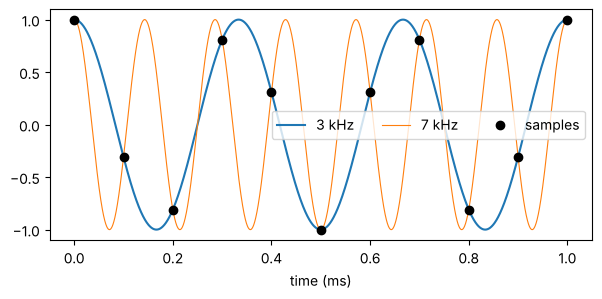

In [7]:
fs = 10e3
n = np.arange(50)
c3, c7, c13 = (np.cos(2 * np.pi * f / fs * n) for f in (3e3, 7e3, 13e3))
print("max |3 kHz - 7 kHz| :", np.max(np.abs(c3 - c7)))
print("max |3 kHz - 13 kHz|:", np.max(np.abs(c3 - c13)))
s3, s7 = (np.sin(2 * np.pi * f / fs * n) for f in (3e3, 7e3))
print("max |sin 3 kHz + sin 7 kHz| (sign flipped):", np.max(np.abs(s3 + s7)))
tt = np.linspace(0, 1e-3, 2001)
plt.figure(figsize=(7, 3))
plt.plot(tt * 1e3, np.cos(2 * np.pi * 3e3 * tt), label="3 kHz")
plt.plot(tt * 1e3, np.cos(2 * np.pi * 7e3 * tt), lw=0.8, label="7 kHz")
plt.plot(n[:11] / fs * 1e3, c3[:11], "ko", label="samples")
plt.xlabel("time (ms)"); plt.legend(ncol=3); plt.show()

**What to take away.** Every definition in the chapter is a computation you can run: periods, energies and powers, transformations and impulses. Part 5 is the seed of aliasing (11-10): once sampled, the 3, 7 and 13 kHz tones are the same signal.